In [138]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import KFold

dataset_original = read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',', engine='python')

# Parse the 'Time' column to datetime and set it as index
dataset_original['Time'] = pd.to_datetime(dataset_original['Time'])
dataset_original.set_index('Time', inplace=True)
dataset_original.sort_index(inplace=True)

# fix random seed for reproducibility
tf.random.set_seed(7)
np.random.seed(7)

# Normalize data
scaler = MinMaxScaler(feature_range=(0, 1))

dataset = scaler.fit_transform(dataset_original[['Parkings', 'day_of_year', 'weekday', 'hour', 'is_holiday']])

def create_sequence(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length,0]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

SEQ_LENGTH = 96
#SEQ_LENGTH = 672


In [139]:

train_size = int(len(dataset) * 0.70)
validation_size = int(len(dataset) * 0.15)
test_size = int(len(dataset) * 0.15)

train_df = dataset[0:train_size]
validation_df = dataset[train_size:train_size+validation_size]
test_df = dataset[train_size+validation_size:]

trainX, trainY = create_sequence(train_df, SEQ_LENGTH)
validationX, validationY = create_sequence(validation_df, SEQ_LENGTH)
testX, testY = create_sequence(test_df, SEQ_LENGTH)


In [140]:
model = Sequential()
model.add(LSTM(8, return_sequences=True, input_shape=(SEQ_LENGTH, trainX.shape[2]), dropout=0.2, recurrent_dropout=0.2))
model.add(LSTM(8, dropout=0.2, recurrent_dropout=0.2))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [141]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
model.fit(trainX, trainY, validation_data=(validationX, validationY), epochs=50, callbacks=[early_stopping])


Epoch 1/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.1035 - val_loss: 0.0232
Epoch 2/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0528 - val_loss: 0.0145
Epoch 3/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0399 - val_loss: 0.0118
Epoch 4/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0323 - val_loss: 0.0118
Epoch 5/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0288 - val_loss: 0.0113
Epoch 6/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0243 - val_loss: 0.0039
Epoch 7/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0213 - val_loss: 0.0042
Epoch 8/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0171 - val_loss: 0.0054
Epoch 9/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0152 - val_loss: 0.0037
Epoch 10/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0149 - val_loss: 0.0043
Epoch 11/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0169 - val_loss: 0.0035
Epoch 12/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 

In [142]:
train_predict = model.predict(trainX)
validation_predict = model.predict(validationX)
test_predict = model.predict(testX)

199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [143]:
# Inverse transform predictions and actual values to original scale
train_predict = scaler.inverse_transform(np.concatenate((train_predict, np.zeros((train_predict.shape[0], dataset.shape[1] - 1))), axis=1))[:, 0]
validation_predict = scaler.inverse_transform(np.concatenate((validation_predict, np.zeros((validation_predict.shape[0], dataset.shape[1] - 1))), axis=1))[:, 0]
test_predict = scaler.inverse_transform(np.concatenate((test_predict, np.zeros((test_predict.shape[0], dataset.shape[1] - 1))), axis=1))[:, 0]
trainY_actual = scaler.inverse_transform(np.concatenate((trainY.reshape(-1, 1), np.zeros((trainY.shape[0], dataset.shape[1] - 1))), axis=1))[:, 0]
validationY_actual = scaler.inverse_transform(np.concatenate((validationY.reshape(-1, 1), np.zeros((validationY.shape[0], dataset.shape[1] - 1))), axis=1))[:, 0]
testY_actual = scaler.inverse_transform(np.concatenate((testY.reshape(-1, 1), np.zeros((testY.shape[0], dataset.shape[1] - 1))), axis=1))[:, 0]

In [144]:
# Calculate MAE and RMSE
train_mae = mean_absolute_error(trainY_actual, train_predict)
train_rmse = np.sqrt(mean_squared_error(trainY_actual, train_predict))
validation_mae = mean_absolute_error(validationY_actual, validation_predict)
validation_rmse = np.sqrt(mean_squared_error(validationY_actual, validation_predict))
test_mae = mean_absolute_error(testY_actual, test_predict)
test_rmse = np.sqrt(mean_squared_error(testY_actual, test_predict))

print(f'Train MAE: {train_mae}, Train RMSE: {train_rmse}')
print(f'Validation MAE: {validation_mae}, Validation RMSE: {validation_rmse}')
print(f'Test MAE: {test_mae}, Test RMSE: {test_rmse}')

Train MAE: 60.858499113283905, Train RMSE: 93.57316094982912
Validation MAE: 45.38227212961479, Validation RMSE: 61.824502074948036
Test MAE: 44.02957566966656, Test RMSE: 56.58274430310208


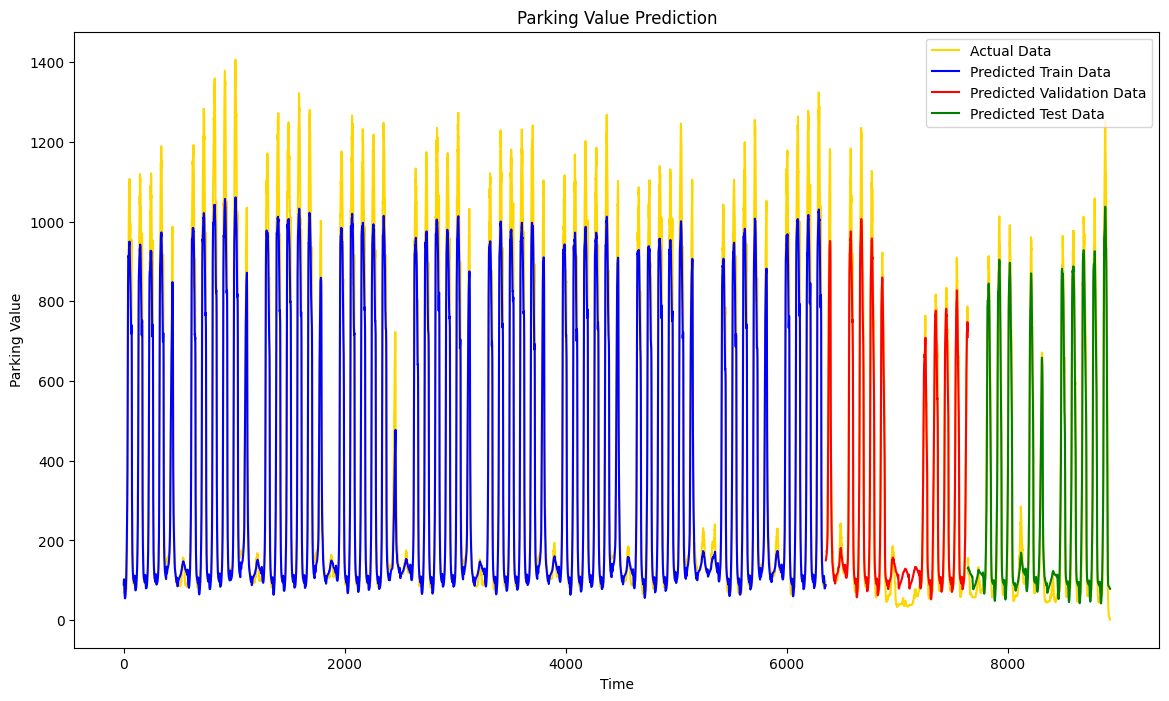

In [145]:
# Plot the results

plt.figure(figsize=(14, 8))

#Plot real data
plt.plot(trainY_actual, label='Actual Data', color='gold')
plt.plot(range(len(trainY_actual), len(trainY_actual) + len(validationY_actual)), validationY_actual, color='gold')
plt.plot(range(len(trainY_actual) + len(validationY_actual), len(trainY_actual) + len(validationY_actual) + len(testY_actual)), testY_actual, color='gold')

plt.plot(train_predict, label='Predicted Train Data', color='b')

plt.plot(range(len(trainY_actual), len(trainY_actual) + len(validationY_actual)), validation_predict, label='Predicted Validation Data', color='r')

plt.plot(range(len(trainY_actual) + len(validationY_actual), len(trainY_actual) + len(validationY_actual) + len(test_predict)), test_predict, label='Predicted Test Data', color='g')

plt.xlabel('Time')
plt.ylabel('Parking Value')
plt.title('Parking Value Prediction')
plt.legend()
plt.show()

Train MAE: 79.20707078048255, Train RMSE: 111.17159128339289
Validation MAE: 89.68032025618051, Validation RMSE: 136.57884643683414
Test MAE: 225.60603376044577, Test RMSE: 273.8992718851497


Train MAE: 68.85680435497805, Train RMSE: 97.89752724345524
Validation MAE: 68.19487680080675, Validation RMSE: 93.531673945741
Test MAE: 67.90646261462912, Test RMSE: 83.7964101207002